# 2. Using your own data

The example city here, **Riverton**, is made up: 12 districts, 7 years of synthetic weekly rates, and a boundary file. It exists to show the formats. Replace the file paths with your own. `data/make_demo_cities.py` shows how the files were made.

You need two things:

| | what | format |
|---|---|---|
| 1 | weekly rates per area | CSV, long (`week, area, rate`) or wide (dates down, areas across) |
| 2 | the map | GeoJSON boundaries **or** a CSV list of bordering pairs |

> **Speed.** To keep this notebook to about half an hour on a laptop, every learned model below uses a 2-member ensemble (`n_seeds=2`) instead of the default 10. Small ensembles are noisier, so treat the numbers here as a demonstration. For real use, drop the `configs=SMALL` argument.

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import areafluforecast as af

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110
import json

## 1. The rates file

Here it's in long format, with one row per district per week. Rates are per 100,000 residents. Leave a week blank when it's missing or suppressed. Never fill it with 0.

In [2]:
raw = pd.read_csv("data/riverton_rates.csv")
raw.head(8)

,week,district,rate
0,2019-06-02,Old Town,NaN
1,2019-06-09,Old Town,2.7
2,2019-06-16,Old Town,2.3
3,2019-06-23,Old Town,3.0
4,2019-06-30,Old Town,NaN
5,2019-07-07,Old Town,2.7
6,2019-07-14,Old Town,4.0
7,2019-07-21,Old Town,4.0


In [3]:
print(f"{raw.district.nunique()} districts, {raw.week.nunique()} weeks, "
      f"{raw.rate.isna().mean():.1%} blank")

12 districts, 366 weeks, 4.1% blank


If you have **counts** rather than rates, `af.rates_from_counts` converts them using each area's population:

In [4]:
counts = pd.DataFrame({"Old Town": [12, 30], "Harbor": [4, 9]},
                      index=pd.to_datetime(["2025-12-07", "2025-12-14"]))
af.rates_from_counts(counts, {"Old Town": 48_000, "Harbor": 21_500})

,Old Town,Harbor
2025-12-07,25.0,18.604651
2025-12-14,62.5,41.860465


## 2. The map

This is a GeoJSON file with one feature per district. Its `district` property matches the names in the rates file. Two features have no data: **North Township** next door and **Lake Erin**. They're *anchors*, which tell the model where the city's edge is and what lies beyond it. The package works out which areas border which by itself.

In [5]:
geo = json.load(open("data/riverton_districts.geojson"))
[f["properties"] for f in geo["features"]][:3] + ["..."]

[{'district': 'Old Town', 'kind': 'district'},
 {'district': 'Harbor', 'kind': 'district'},
 {'district': 'Millbrook', 'kind': 'district'},
 '...']

## 3. Build the city and check it

Build it with `City.from_files`, then read `summary()` before training anything.

In [6]:
city = af.City.from_files(
    "data/riverton_rates.csv",
    areas="data/riverton_districts.geojson", id_col="district",   # the GeoJSON property
    area_col="district",                                         # the rates column
    anchors=["North Township", "Lake Erin"],
    flu_months=(10, 11, 12, 1, 2, 3),       # Southern Hemisphere: e.g. (4, 5, 6, 7, 8, 9)
    name="riverton")
print(city.summary())

riverton: 12 areas, 366 weeks (2019-06-02 to 2026-05-31), flu season Oct-Mar
  graph: 17 borders between areas, 2 anchors with 7 borders
  missing area-weeks: 4.1%
  weather: no | static characteristics: none
  complete seasons available to backtest: 2022-23, 2023-24, 2024-25, 2025-26


**Check the map.** A wrong border here means the model gets wrong information, so plot it. Grey lines are borders between districts and dashed lines are borders to anchors.

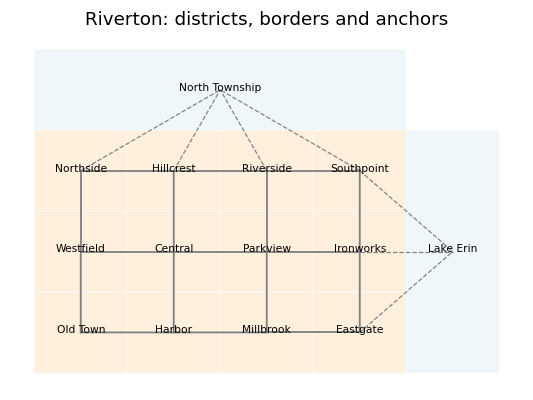

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for f in geo["features"]:
    ring = f["geometry"]["coordinates"][0]
    is_anchor = f["properties"]["kind"] == "anchor"
    ax.fill(*zip(*ring), alpha=0.15 if is_anchor else 0.35,
            color="#9ecae1" if is_anchor else "#fdd49e", ec="white")
cent = city.centroids
for a, b in city.edges:
    ax.plot(*zip(cent[a][::-1], cent[b][::-1]), color="grey", lw=1.2)
for a, b in city.anchor_edges:
    ax.plot(*zip(cent[a][::-1], cent[b][::-1]), color="grey", lw=0.8, ls="--")
for name, (lat, lon) in cent.items():
    ax.annotate(name, (lon, lat), ha="center", fontsize=7)
ax.set_axis_off(); ax.set_title("Riverton: districts, borders and anchors");

### What a mistake looks like

The package refuses data it can't use and says what to fix. Here are two common ones.

In [8]:
try:
    af.City(name="typo", rates=city.rates, edges=city.edges + [("Old Town", "Old Twon")])
except af.DataError as err:
    print("DataError:", err)

DataError: Edges mention ['Old Twon'], which are not columns of the rates. Fix the spelling, or list boundary nodes without data in anchors=[...].


In [9]:
try:
    af.City(name="short", rates=city.rates.iloc[-60:], edges=city.edges)
except af.DataError as err:
    print("DataError:", err)

DataError: Only 60 weeks of data; at least two years (104 weeks) are needed to learn a season.


> **Boundary files that don't line up.** Borders are found where polygons share vertices, which is how Census TIGER and most city open-data files are drawn. If your districts were digitised separately and leave small gaps, use `af.adjacency.adjacency_from_polygons(features, "district", method="touches")` (needs `pip install shapely`) and pass the result as `edges=`. Check the plot afterwards.

## 4. Weather (optional)

`city.fetch_weather()` downloads weekly weather at each district's centre from Open-Meteo. It's free and needs no key, and the downloads are cached. In the research behind this package, weather helped the graph model a little. Riverton is fictional, so it's left off here.

In [10]:
FETCH_WEATHER = False
if FETCH_WEATHER:
    city.fetch_weather()

## 5. Backtest and forecast

This is the same two calls as the Boston notebook. Riverton has four complete seasons, and we backtest the last two.

In [11]:
SMALL = {"gnn_st": {"n_seeds": 2}, "lstm": {"n_seeds": 2}, "colagnn": {"n_seeds": 2}}

bt = af.backtest(city, seasons=2, horizons=(1, 2), configs=SMALL, out_dir="runs")

Budget: 32 epochs x 1 seeds


--- seed 1 (1/1) ---


riverton: 12 areas, 366 weeks (2019-06-02 to 2026-05-31), flu season Oct-Mar
  graph: 17 borders between areas, 2 anchors with 7 borders
  missing area-weeks: 4.1%
  weather: no | static characteristics: none
  complete seasons available to backtest: 2022-23, 2023-24, 2024-25, 2025-26


Epoch 1 |   3.1% | 2024-25 1wk gnn_st seed 42 | elapsed 2m46s | left ~1h26m


Epoch 2 |   6.2% | 2024-25 1wk gnn_st seed 43 | elapsed 5m27s | left ~1h21m


...

Epoch 30 |  93.8% | 2025-26 2wk colagnn seed 43 | elapsed 25m37s | left ~1m42s


Epoch 31 |  96.9% | 2025-26 2wk persistence | elapsed 25m37s | left ~0m49s


Epoch 32 | 100.0% | 2025-26 2wk seasonal_naive | elapsed 25m37s | left ~0m00s


Outputs: runs/riverton/backtest_20261004-235407


# Backtest: riverton

Seasons: 2024-25, 2025-26. Every number is from weeks the models never trained on.

**Relative WIS** is the model's weighted interval score divided by persistence's on the same weeks: below 1 means it beat "next week looks like this week". **p (Holm)** asks whether the weekly gap is bigger than week-to-week noise, adjusted for the number of comparisons.

| weeks ahead | model | WIS | relative WIS | p (Holm) | verdict |
|---|---|---|---|---|---|
| 1 | gnn_st | 1.30 | 0.73 | 0.000 | better than persistence |
| 1 | colagnn | 1.34 | 0.75 | 0.000 | better than persistence |
| 1 | lstm | 1.61 | 0.90 | 0.007 | better than persistence |
| 1 | seasonal_naive | 4.60 | 2.57 | 0.000 | worse than persistence |
| 2 | gnn_st | 1.60 | 0.54 | 0.000 | better than persistence |
| 2 | colagnn | 1.83 | 0.61 | 0.003 | better than persistence |
| 2 | lstm | 1.93 | 0.65 | 0.000 | better than persistence |
| 2 | seasonal_naive | 4.60 | 1.54 | 0.007 | worse than persistence |

Coverage of 

In [12]:
bt.comparison[["horizon", "model", "wis", "relative_wis", "p_holm", "verdict"]].sort_values(["horizon", "relative_wis"]).round(3)

,horizon,model,wis,relative_wis,p_holm,verdict
1,1,gnn_st,1.298,0.725,0.000,better than persistence
0,1,colagnn,1.338,0.747,0.000,better than persistence
2,1,lstm,1.611,0.900,0.007,better than persistence
3,1,seasonal_naive,4.602,2.570,0.000,worse than persistence
5,2,gnn_st,1.600,0.537,0.000,better than persistence
4,2,colagnn,1.829,0.614,0.003,better than persistence
6,2,lstm,1.930,0.648,0.000,better than persistence
7,2,seasonal_naive,4.602,1.544,0.007,worse than persistence


Budget: 12 epochs x 1 seeds


--- seed 1 (1/1) ---


Epoch 1 |   8.3% | 1wk gnn_st seed 42 | elapsed 3m22s | left ~37m04s


Epoch 2 |  16.7% | 1wk gnn_st seed 43 | elapsed 6m41s | left ~33m29s


Epoch 3 |  25.0% | 1wk lstm seed 42 | elapsed 6m43s | left ~20m09s


...

Epoch 9 |  75.0% | 2wk lstm seed 42 | elapsed 14m21s | left ~4m47s


Epoch 10 |  83.3% | 2wk lstm seed 43 | elapsed 14m23s | left ~2m52s


Epoch 11 |  91.7% | 2wk colagnn seed 42 | elapsed 14m57s | left ~1m21s


Epoch 12 | 100.0% | 2wk colagnn seed 43 | elapsed 15m31s | left ~0m00s


Outputs: runs/riverton/forecast_20261004-235408


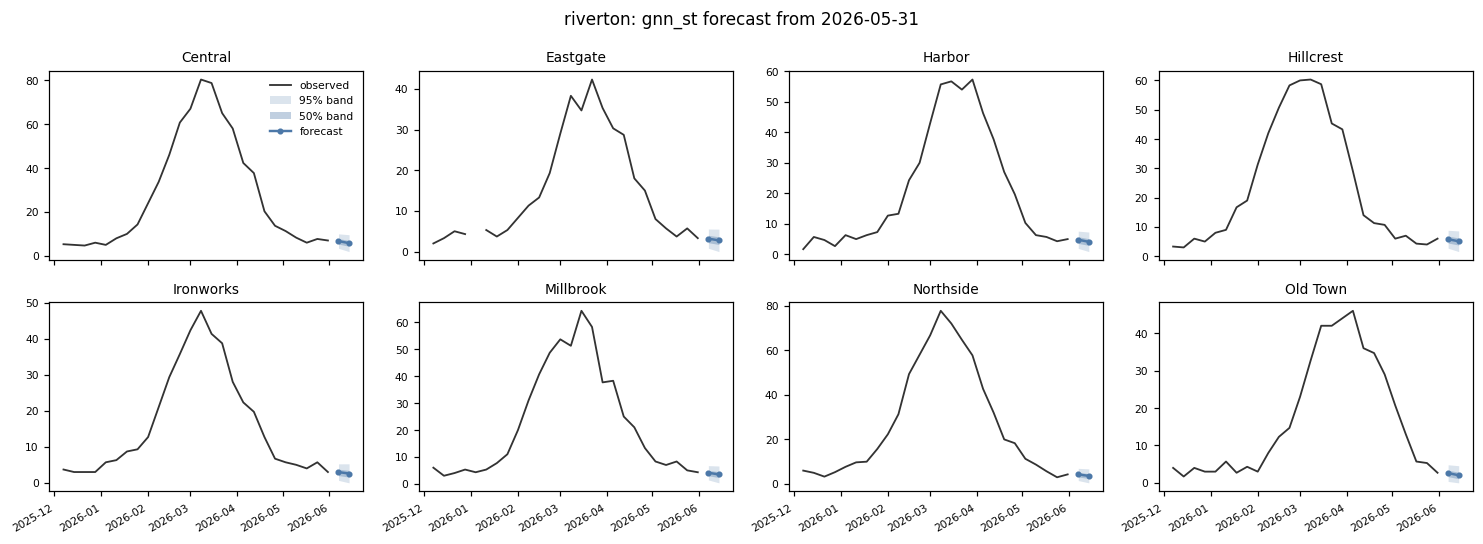

In [13]:
fc = af.forecast(city, horizons=(1, 2), configs=SMALL, out_dir="runs")
fig = fc.plot("gnn_st", areas=city.areas[:8])

Riverton's epidemics spread from district to district along borders, so a model that uses the map has real information to work with here. Whether your city behaves like this is exactly what the backtest tells you.